# 08. Convolutional Neural Networks (CNNs) with TensorFlow

**Deep Learning with TensorFlow | Part III — Deep Learning Architectures**

This notebook introduces convolutional neural networks for image classification. It moves from the mechanics of convolution and pooling to a complete, reproducible image-classification workflow using Keras.

> **Educational dataset notice:** The practical project uses procedurally generated cell-like images. These images are synthetic teaching examples, not real microscopy data, and the resulting model has no clinical meaning.

---

## Notebook Map

1. Computer vision and image tensors
2. Convolution, kernels, stride, padding, and output dimensions
3. Feature maps and pooling
4. CNN architecture and parameter counting
5. A reproducible synthetic image dataset
6. Data splitting, batching, and augmentation
7. Building and training a CNN with Keras
8. Evaluation, error analysis, and feature-map inspection
9. Exercises and further reading

## Learning Objectives

By the end of this notebook, you should be able to:

- Represent grayscale and color images as tensors and explain the channels-last convention.
- Describe how a convolutional filter detects local patterns.
- Calculate the spatial output shape of a convolution or pooling operation.
- Explain the roles of filters, kernels, stride, padding, activation functions, and pooling.
- Estimate the number of trainable parameters in a convolutional layer.
- Build an image input pipeline and apply label-preserving augmentation.
- Construct, train, and evaluate a CNN with Keras.
- Inspect predictions, confusion matrices, misclassified examples, and intermediate feature maps.

## Prerequisites

The notebook assumes familiarity with Python, NumPy arrays, train/validation/test splitting, classification metrics, and the basic Keras workflow from Notebooks 03–07.

## 1. Computer Vision: Why Use Convolutional Networks?

An image contains spatial structure. Nearby pixels are related, edges form local patterns, and local patterns combine into larger shapes. A fully connected network can learn from flattened pixels, but it does not encode this spatial structure directly and usually requires many parameters.

A convolutional neural network (CNN) uses small learnable kernels that are applied across an image. The same kernel is reused at different spatial locations. This gives CNNs **local connectivity** and **parameter sharing**.

| Fully connected approach | Convolutional approach |
|---|---|
| Flatten the image into a vector | Preserve height, width, and channels |
| Separate weights for many input locations | Reuse each kernel across locations |
| Spatial locality is not built into the layer | Local receptive fields are explicit |
| Often many parameters for image inputs | Parameter count depends mainly on kernel and channel sizes |

CNNs are not automatically better for every dataset. Performance still depends on data quality, sample size, preprocessing, architecture, and evaluation design.

## 2. Images as Tensors

For a single grayscale image, the typical channels-last shape is:

$$
(H, W, 1)
$$

For a single RGB image:

$$
(H, W, 3)
$$

A batch of RGB images has shape:

$$
(N, H, W, 3)
$$

where $N$ is the batch size, $H$ is image height, and $W$ is image width. In this notebook, we use grayscale images with shape $(64, 64, 1)$ and batches with shape $(N, 64, 64, 1)$.

Pixel values are represented as floating-point numbers in the range $[0, 1]$ after scaling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Illustrative image shapes
height, width = 64, 64
grayscale_image = np.zeros((height, width, 1), dtype=np.float32)
rgb_image = np.zeros((height, width, 3), dtype=np.float32)
image_batch = np.zeros((16, height, width, 1), dtype=np.float32)

print("Grayscale image:", grayscale_image.shape)
print("RGB image:", rgb_image.shape)
print("Grayscale batch:", image_batch.shape)

Grayscale image: (64, 64, 1)
RGB image: (64, 64, 3)
Grayscale batch: (16, 64, 64, 1)


### Visualizing an Image Tensor

The next example creates a simple synthetic image to make the height, width, and intensity channel concrete.

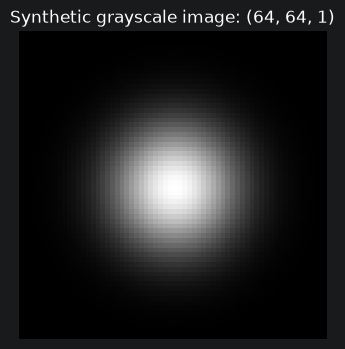

In [2]:
y_grid, x_grid = np.mgrid[0:64, 0:64]
example_image = np.exp(-((x_grid - 32) ** 2 + (y_grid - 32) ** 2) / (2 * 9 ** 2))
example_image = example_image[..., np.newaxis].astype(np.float32)

plt.figure(figsize=(4, 4))
plt.imshow(example_image[..., 0], cmap="gray", vmin=0, vmax=1)
plt.title(f"Synthetic grayscale image: {example_image.shape}")
plt.axis("off")
plt.show()

## 3. The Convolution Operation

A convolutional layer slides a small kernel over the input. At each spatial position, it computes element-wise products between the kernel and the local image patch, then sums the products (and usually adds a bias).

For a single-channel input and one kernel, a local output can be written as:

$$
z_{i,j} = \sum_{u=0}^{K_h-1}\sum_{v=0}^{K_w-1} x_{iS_h+u,\,jS_w+v}\,k_{u,v} + b
$$

where $x$ is the input, $k$ is the kernel, $b$ is the bias, and $S_h,S_w$ are the vertical and horizontal strides.

In deep-learning libraries, the operation commonly called convolution is implemented as **cross-correlation**: the kernel is not flipped before the element-wise multiplication. The learned operation is still conventionally called convolution.

### A Small Convolution by Hand

Use a $3\times3$ kernel to compute one output value from a $3\times3$ image patch. This example is deliberately small enough to verify manually.

In [3]:
patch = np.array([
    [1, 2, 1],
    [0, 1, 3],
    [2, 1, 0],
], dtype=np.float32)

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
], dtype=np.float32)

products = patch * kernel
output_value = products.sum()
print("Element-wise products:\n", products)
print("Convolution-style response:", output_value)

Element-wise products:
 [[ 1.  0. -1.]
 [ 0.  0. -3.]
 [ 2.  0. -0.]]
Convolution-style response: -1.0


### Slide a Kernel Across an Image

The next function implements a valid, single-channel 2D cross-correlation with an optional stride. It is a teaching implementation, not a replacement for optimized convolution libraries.

In [4]:
def cross_correlate_valid(image, kernel, stride=1):
    """Compute a valid 2D cross-correlation for single-channel arrays."""
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("image and kernel must both be 2D arrays")
    if isinstance(stride, int):
        stride_h = stride_w = stride
    else:
        stride_h, stride_w = stride
    if stride_h <= 0 or stride_w <= 0:
        raise ValueError("stride values must be positive")
    kh, kw = kernel.shape
    if image.shape[0] < kh or image.shape[1] < kw:
        raise ValueError("kernel cannot be larger than the image for valid padding")
    out_h = (image.shape[0] - kh) // stride_h + 1
    out_w = (image.shape[1] - kw) // stride_w + 1
    result = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        for j in range(out_w):
            r0, c0 = i * stride_h, j * stride_w
            local_patch = image[r0:r0 + kh, c0:c0 + kw]
            result[i, j] = np.sum(local_patch * kernel)
    return result

sample_image = np.arange(1, 26, dtype=np.float32).reshape(5, 5)
sobel_like_kernel = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=np.float32)
feature_response = cross_correlate_valid(sample_image, sobel_like_kernel, stride=1)
print("Input shape:", sample_image.shape)
print("Output shape:", feature_response.shape)
print(feature_response)

Input shape: (5, 5)
Output shape: (3, 3)
[[-8. -8. -8.]
 [-8. -8. -8.]
 [-8. -8. -8.]]


## 4. Filters and Kernels

A kernel contains learnable weights. Early filters may respond to simple local structures such as edges or intensity transitions. Deeper layers can combine lower-level responses into more complex patterns. The exact meaning of a learned filter should not be inferred from a single visualization alone.

Common hand-designed examples include:

- Horizontal or vertical edge detectors
- Blur kernels
- Sharpening kernels

A CNN generally learns its kernels from training data by minimizing a loss function through backpropagation.

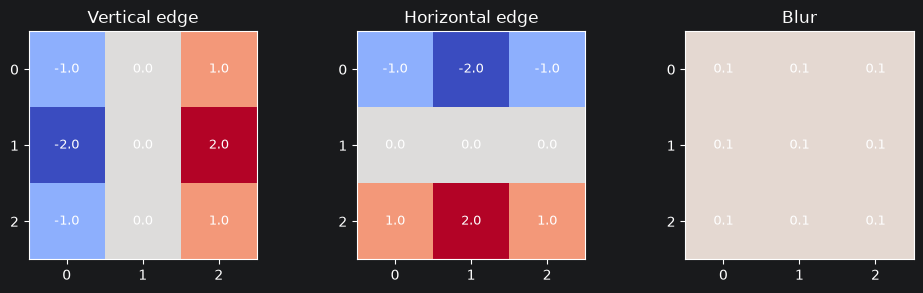

In [5]:
edge_kernels = {
    "Vertical edge": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    "Horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    "Blur": np.ones((3, 3), dtype=np.float32) / 9.0,
}

fig, axes = plt.subplots(1, len(edge_kernels), figsize=(10, 3))
for ax, (name, values) in zip(axes, edge_kernels.items()):
    ax.imshow(values, cmap="coolwarm", vmin=-2, vmax=2)
    ax.set_title(name)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{values[r, c]:.1f}", ha="center", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Stride, Padding, and Output Dimensions

**Stride** controls how far the kernel moves between adjacent positions. A stride larger than one reduces the spatial resolution more quickly.

**Padding** controls how the input borders are handled:

- `valid`: no padding is added, so the kernel only visits positions fully inside the input.
- `same`: padding is selected so that, for stride one, the output height and width match the input height and width.

For one spatial dimension, valid convolution has output size:

$$
O = \left\lfloor \frac{I + 2P - K}{S} \right\rfloor + 1
$$

where $I$ is input size, $K$ is kernel size, $P$ is padding on one side, and $S$ is stride. For `same` padding, the output size is commonly:

$$
O = \left\lceil \frac{I}{S} \right\rceil
$$

The height and width are calculated separately.

In [6]:
import math

def conv_output_size(input_size, kernel_size, stride=1, padding=0):
    """Output size for one spatial dimension using explicit symmetric padding."""
    return math.floor((input_size + 2 * padding - kernel_size) / stride) + 1

print("Valid: input=32, kernel=3, stride=1 ->", conv_output_size(32, 3, 1, 0))
print("Valid: input=32, kernel=3, stride=2 ->", conv_output_size(32, 3, 2, 0))
print("Same:  input=32, stride=2 ->", math.ceil(32 / 2))

Valid: input=32, kernel=3, stride=1 -> 30
Valid: input=32, kernel=3, stride=2 -> 15
Same:  input=32, stride=2 -> 16


### Check the Shapes

For a $64\times64$ image, a $3\times3$ kernel, stride 1, and `same` padding, the output spatial size remains $64\times64$. With `valid` padding, the output becomes $62\times62$. If stride is 2 with `same` padding, the output becomes $32\times32$.

In [7]:
shape_examples = [
    (64, 3, 1, 0),  # valid
    (64, 3, 1, 1),  # explicit padding 1
    (64, 3, 2, 0),  # valid, stride 2
]
for input_size, kernel_size, stride, padding in shape_examples:
    print((input_size, kernel_size, stride, padding), "->", conv_output_size(input_size, kernel_size, stride, padding))

(64, 3, 1, 0) -> 62
(64, 3, 1, 1) -> 64
(64, 3, 2, 0) -> 31


## 6. Multiple Filters and Feature Maps

A convolutional layer usually contains multiple filters. Each filter produces one output channel, so a layer with 32 filters produces 32 feature maps.

For channels-last data, a convolutional layer receives a tensor shaped like $(H,W,C_{in})$ and returns $(H_{out},W_{out},C_{out})$. Each filter spans all input channels.

The parameter count for a standard convolutional layer with bias is:

$$
(K_h K_w C_{in} + 1) C_{out}
$$

The `+1` represents one bias per output channel.

In [8]:
def conv2d_parameter_count(kernel_height, kernel_width, input_channels, filters, use_bias=True):
    weights = kernel_height * kernel_width * input_channels * filters
    biases = filters if use_bias else 0
    return weights + biases

print("3x3, 1 input channel, 32 filters:", conv2d_parameter_count(3, 3, 1, 32))
print("3x3, 32 input channels, 64 filters:", conv2d_parameter_count(3, 3, 32, 64))

3x3, 1 input channel, 32 filters: 320
3x3, 32 input channels, 64 filters: 18496


## 7. Pooling Layers

Pooling reduces the spatial dimensions of feature maps. **Max pooling** keeps the largest value in each window; **average pooling** computes the average value.

For a $2\times2$ max-pooling window with stride 2, each non-overlapping $2\times2$ region becomes one value. Pooling is a downsampling operation; it does not learn a kernel in the same way as a convolutional layer.

In [9]:
def max_pool2d_valid(array, pool_size=2, stride=2):
    array = np.asarray(array)
    if array.ndim != 2:
        raise ValueError("array must be 2D")
    if isinstance(pool_size, int):
        ph = pw = pool_size
    else:
        ph, pw = pool_size
    sh = sw = stride if isinstance(stride, int) else stride[0]
    if not isinstance(stride, int):
        sh, sw = stride
    out_h = (array.shape[0] - ph) // sh + 1
    out_w = (array.shape[1] - pw) // sw + 1
    output = np.empty((out_h, out_w), dtype=array.dtype)
    for i in range(out_h):
        for j in range(out_w):
            r, c = i * sh, j * sw
            output[i, j] = np.max(array[r:r + ph, c:c + pw])
    return output

pool_input = np.array([[1, 3, 2, 0], [4, 6, 1, 2], [2, 8, 5, 3], [1, 2, 7, 4]])
print("Input:\n", pool_input)
print("Max pooled:\n", max_pool2d_valid(pool_input, pool_size=2, stride=2))

Input:
 [[1 3 2 0]
 [4 6 1 2]
 [2 8 5 3]
 [1 2 7 4]]
Max pooled:
 [[6 2]
 [8 7]]


### Flattening vs. Global Average Pooling

`Flatten` converts all spatial values into one long vector. `GlobalAveragePooling2D` averages each feature map over its spatial positions, producing one value per channel.

Global average pooling often creates a smaller classifier head and can reduce the number of dense-layer parameters. It does not preserve the exact spatial arrangement of activations, so the choice depends on the task and architecture.

## 8. A Basic CNN Architecture

A common introductory pattern is:

1. Convolution + nonlinearity
2. Spatial downsampling (often max pooling)
3. Repeat with more filters
4. Convert feature maps into a compact representation
5. Dense classification head

For a $64\times64$ grayscale image, two $2\times2$ pooling operations reduce the spatial size from $64\times64$ to $16\times16$. A third pooling operation reduces it to $8\times8$.

The architecture below is a teaching baseline, not a universal best architecture. ResNet, EfficientNet, U-Net, and Vision Transformers are covered elsewhere in the roadmap or as extensions.

## 9. Practical Project: Synthetic Cell-Like Image Classification

We will classify three deliberately simplified image patterns:

- `round`: one approximately circular cell-like object
- `elongated`: one elongated cell-like object
- `clustered`: a small group of overlapping circular objects

The generated images vary in position, scale, orientation, intensity, and background noise. This variation makes the task more realistic than classifying three fixed templates, while keeping the dataset small and reproducible.

**Important limitation:** These are algorithmically generated shapes. They do not represent cell biology, pathology, or any clinical diagnosis. The project teaches image classification mechanics only.

### 9.1 Imports and Reproducibility

We use TensorFlow with the Keras 3 API. The code checks the installed versions and sets a reproducible random seed. Exact numerical reproducibility can still depend on hardware and low-level kernels.

In [10]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)

NumPy: 2.4.6


In [11]:
import tensorflow as tf
import keras

keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Keras backend:", keras.backend.backend())

TensorFlow: 2.21.0
Keras: 3.15.1
Keras backend: tensorflow


### 9.2 Generate Synthetic Images

The generator draws a simple foreground shape on a noisy grayscale background. Each class has randomized geometric parameters. We use floating-point images in $[0,1]$ and add the channel dimension required by a 2D CNN.

In [12]:
IMAGE_SIZE = 64
CLASS_NAMES = ["round", "elongated", "clustered"]
NUM_CLASSES = len(CLASS_NAMES)


def generate_cell_like_image(class_id, rng, image_size=IMAGE_SIZE):
    """Generate one synthetic grayscale image for a morphology teaching task."""
    yy, xx = np.mgrid[0:image_size, 0:image_size]
    cx = rng.uniform(image_size * 0.38, image_size * 0.62)
    cy = rng.uniform(image_size * 0.38, image_size * 0.62)
    background = rng.uniform(0.02, 0.10)
    image = np.full((image_size, image_size), background, dtype=np.float32)

    cell_intensity = rng.uniform(0.38, 0.62)
    nucleus_intensity = rng.uniform(0.72, 0.95)

    if class_id == 0:  # round
        rx = rng.uniform(9, 13)
        ry = rng.uniform(9, 13)
        body = ((xx - cx) / rx) ** 2 + ((yy - cy) / ry) ** 2 <= 1
        image[body] = cell_intensity
        nx, ny = cx + rng.uniform(-2, 2), cy + rng.uniform(-2, 2)
        nucleus = ((xx - nx) / 3.5) ** 2 + ((yy - ny) / 3.5) ** 2 <= 1
        image[nucleus] = nucleus_intensity

    elif class_id == 1:  # elongated
        angle = rng.uniform(0, np.pi)
        major = rng.uniform(17, 21)
        minor = rng.uniform(5, 8)
        xr = (xx - cx) * np.cos(angle) + (yy - cy) * np.sin(angle)
        yr = -(xx - cx) * np.sin(angle) + (yy - cy) * np.cos(angle)
        body = (xr / major) ** 2 + (yr / minor) ** 2 <= 1
        image[body] = cell_intensity
        nucleus = (xr / 5.0) ** 2 + (yr / 2.7) ** 2 <= 1
        image[nucleus] = nucleus_intensity

    elif class_id == 2:  # clustered
        offsets = [(-7, -4), (7, -3), (0, 8)]
        for ox, oy in offsets:
            local_cx = cx + ox + rng.uniform(-2, 2)
            local_cy = cy + oy + rng.uniform(-2, 2)
            radius = rng.uniform(7.5, 10.5)
            body = (xx - local_cx) ** 2 + (yy - local_cy) ** 2 <= radius ** 2
            image[body] = np.maximum(image[body], cell_intensity)
            nucleus = (xx - local_cx) ** 2 + (yy - local_cy) ** 2 <= (radius * 0.28) ** 2
            image[nucleus] = nucleus_intensity
    else:
        raise ValueError("class_id must be 0, 1, or 2")

    # Mild smooth intensity variation and sensor-like noise.
    illumination = rng.uniform(0.92, 1.08)
    image *= illumination
    image += rng.normal(0, 0.025, size=image.shape).astype(np.float32)
    image = np.clip(image, 0.0, 1.0)
    return image[..., np.newaxis].astype(np.float32)

In [13]:
SAMPLES_PER_CLASS = 300
rng = np.random.default_rng(SEED)

images = []
labels = []
for class_id in range(NUM_CLASSES):
    for _ in range(SAMPLES_PER_CLASS):
        images.append(generate_cell_like_image(class_id, rng))
        labels.append(class_id)

X = np.stack(images).astype(np.float32)
y = np.asarray(labels, dtype=np.int64)

# Shuffle once before displaying and splitting.
permutation = rng.permutation(len(y))
X = X[permutation]
y = y[permutation]

print("Image tensor:", X.shape)
print("Label vector:", y.shape)
print("Pixel range:", (float(X.min()), float(X.max())))
print("Class counts:", dict(zip(CLASS_NAMES, np.bincount(y))))

Image tensor: (900, 64, 64, 1)
Label vector: (900,)
Pixel range: (0.0, 1.0)
Class counts: {'round': np.int64(300), 'elongated': np.int64(300), 'clustered': np.int64(300)}


### 9.3 Explore the Images

Inspect multiple examples per class before training. Visual inspection can reveal label errors, artifacts, or unintended shortcuts in a dataset.

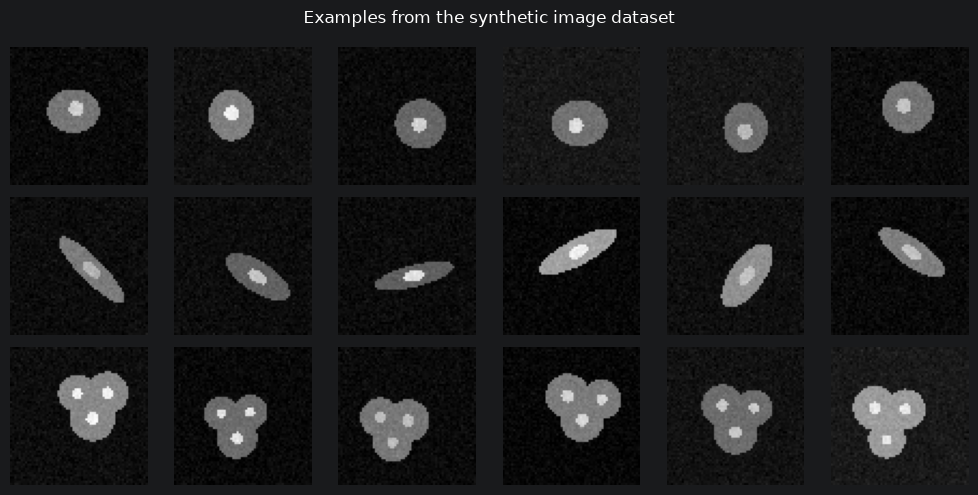

In [14]:
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(10, 5))
for class_id, class_name in enumerate(CLASS_NAMES):
    class_indices = np.flatnonzero(y == class_id)[:6]
    for col, index in enumerate(class_indices):
        axes[class_id, col].imshow(X[index, ..., 0], cmap="gray", vmin=0, vmax=1)
        axes[class_id, col].axis("off")
        if col == 0:
            axes[class_id, col].set_ylabel(class_name, rotation=0, labelpad=48, va="center")
plt.suptitle("Examples from the synthetic image dataset")
plt.tight_layout()
plt.show()

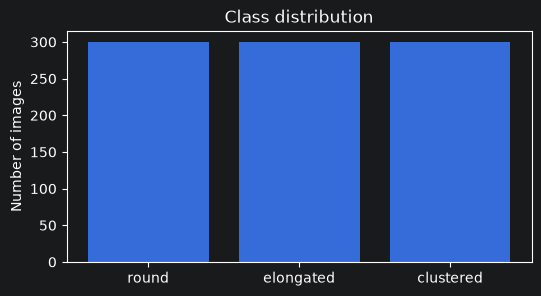

In [15]:
class_counts = np.bincount(y, minlength=NUM_CLASSES)
plt.figure(figsize=(6, 3))
plt.bar(CLASS_NAMES, class_counts)
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.show()

### 9.4 Train, Validation, and Test Splits

We use stratified splitting so that each subset preserves approximately the same class proportions. The test set is held aside until final evaluation.

The synthetic dataset is balanced, but stratification is still useful because it makes the intended evaluation design explicit.

In [16]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Train:", X_train.shape, np.bincount(y_train))
print("Validation:", X_val.shape, np.bincount(y_val))
print("Test:", X_test.shape, np.bincount(y_test))

Train: (630, 64, 64, 1) [210 210 210]
Validation: (135, 64, 64, 1) [45 45 45]
Test: (135, 64, 64, 1) [45 45 45]


### 9.5 Input Pipeline with `tf.data`

Our generator already creates pixel values in $[0,1]$, so no dataset-fitted normalization statistics are needed. We build batched datasets and prefetch batches to overlap data preparation with model execution.

The training dataset is shuffled. Validation and test datasets are not shuffled, making later prediction-to-label comparisons straightforward.

In [17]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

for batch_images, batch_labels in train_ds.take(1):
    print("Batch images:", batch_images.shape)
    print("Batch labels:", batch_labels.shape)

Batch images: (32, 64, 64, 1)
Batch labels: (32,)


## 10. Image Augmentation

Data augmentation creates label-preserving variations of training images. For this synthetic morphology task, horizontal flips, vertical flips, and small rotations preserve the class definition.

Augmentation should reflect plausible transformations for the real task. For example, a vertical flip may be inappropriate when image orientation carries meaning. Augmentation layers in Keras are active during training and inactive during ordinary inference.

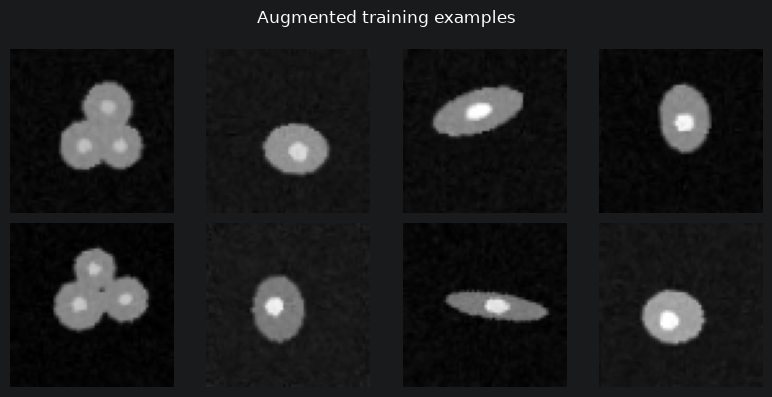

In [18]:
augmentation = keras.Sequential(
    [
        keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        keras.layers.RandomRotation(0.08, fill_mode="reflect", seed=SEED + 1),
        keras.layers.RandomZoom(0.08, fill_mode="reflect", seed=SEED + 2),
        keras.layers.RandomContrast(0.10, seed=SEED + 3),
    ],
    name="data_augmentation",
)

sample_batch = tf.convert_to_tensor(X_train[:8])
augmented_batch = augmentation(sample_batch, training=True).numpy()

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, image in zip(axes.ravel(), augmented_batch):
    ax.imshow(np.clip(image[..., 0], 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Augmented training examples")
plt.tight_layout()
plt.show()

## 11. Build a CNN with Keras

The model uses three convolutional blocks. Each block applies a convolution with `same` padding, a ReLU activation, and max pooling. `GlobalAveragePooling2D` then summarizes each feature map before a small dense classification head.

The output layer has three units with softmax activation because the task has three mutually exclusive classes. We use integer labels with `SparseCategoricalCrossentropy`.

In [19]:
inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1), name="image")
x = augmentation(inputs)

x = keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="conv1")(x)
x = keras.layers.MaxPooling2D(pool_size=2, name="pool1")(x)

x = keras.layers.Conv2D(64, kernel_size=3, padding="same", activation="relu", name="conv2")(x)
x = keras.layers.MaxPooling2D(pool_size=2, name="pool2")(x)

x = keras.layers.Conv2D(128, kernel_size=3, padding="same", activation="relu", name="conv3")(x)
x = keras.layers.MaxPooling2D(pool_size=2, name="pool3")(x)

x = keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = keras.layers.Dense(64, activation="relu", name="dense_features")(x)
x = keras.layers.Dropout(0.30, name="classifier_dropout")(x)
outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="synthetic_cell_cnn")
model.summary()

Model: "synthetic_cell_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,123 (395.01 KB)

 Trainable params: 101,123 (395.01 KB)

 Non-trainable params: 0 (0.00 B)

### 11.1 Inspect the Layer Shapes

The convolutional layers preserve spatial dimensions because they use `padding="same"` and stride 1. Each max-pooling layer halves height and width. The number of channels increases with the number of filters.

| Stage | Output shape (excluding batch) |
|---|---|
| Input | $64\times64\times1$ |
| Conv 1 | $64\times64\times32$ |
| Pool 1 | $32\times32\times32$ |
| Conv 2 | $32\times32\times64$ |
| Pool 2 | $16\times16\times64$ |
| Conv 3 | $16\times16\times128$ |
| Pool 3 | $8\times8\times128$ |
| Global average pooling | $128$ |
| Dense features | $64$ |
| Softmax output | $3$ |

In [20]:
for layer in model.layers:
    try:
        print(f"{layer.name:28s} {layer.output.shape}")
    except AttributeError:
        print(f"{layer.name:28s} output shape not available before build")

image                        (None, 64, 64, 1)
data_augmentation            (None, 64, 64, 1)
conv1                        (None, 64, 64, 32)
pool1                        (None, 32, 32, 32)
conv2                        (None, 32, 32, 64)
pool2                        (None, 16, 16, 64)
conv3                        (None, 16, 16, 128)
pool3                        (None, 8, 8, 128)
global_average_pooling       (None, 128)
dense_features               (None, 64)
classifier_dropout           (None, 64)
class_probabilities          (None, 3)


### 11.2 Compile the Model

For mutually exclusive multiclass classification with integer-encoded labels, use sparse categorical cross-entropy. The model returns one probability per class, and the probabilities sum to approximately one for each image.

In [21]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

## 12. Train the CNN

Early stopping monitors validation loss and restores the weights from the best observed epoch. The test set is not used for model selection.

The dataset is intentionally small. On CPU, training should be manageable, but runtime depends on the local TensorFlow build and hardware. Reduce `EPOCHS` or the number of samples per class if needed for a quick first run.

In [22]:
EPOCHS = 20

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/20


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 296ms/step - accuracy: 0.3159 - loss: 1.0987 - val_accuracy: 0.3333 - val_loss: 1.0930
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 340ms/step - accuracy: 0.3349 - loss: 1.0894 - val_accuracy: 0.3333 - val_loss: 1.0785
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - accuracy: 0.3365 - loss: 1.0729 - val_accuracy: 0.3333 - val_loss: 1.0615
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.3667 - loss: 1.0602 - val_accuracy: 0.5407 - val_loss: 1.0262
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.5365 - loss: 1.0079 - val_accuracy: 0.6667 - val_loss: 0.9253
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.5730 - loss: 0.8718 - val_accuracy: 0.6222 - val_loss: 0.7922
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.5571 - loss: 0.8335 - val_accuracy: 0.6593 - val_loss: 0.6988
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.5937 - loss: 0.7513 - val_accuracy: 0.6370 - val_

### 12.1 Plot Training Curves

Compare training and validation loss and accuracy. A widening gap may indicate overfitting, while both curves remaining poor may indicate underfitting or an optimization/data problem.

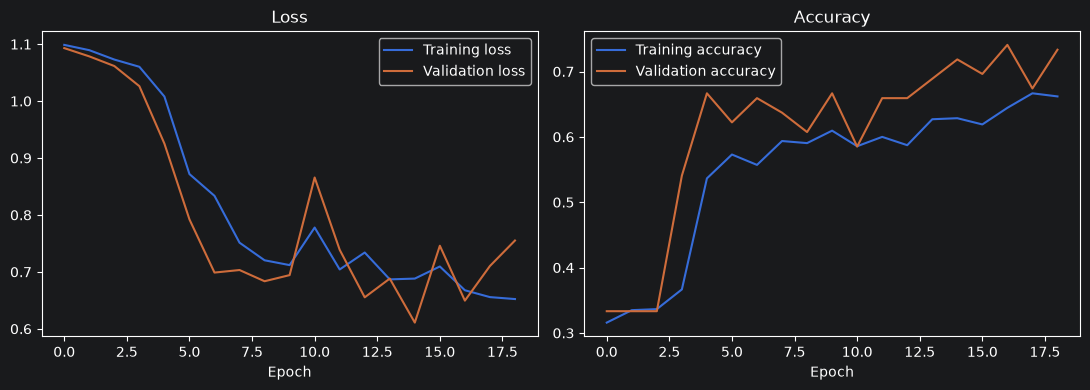

In [23]:
history_dict = history.history

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_dict["loss"], label="Training loss")
axes[0].plot(history_dict["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_dict["accuracy"], label="Training accuracy")
axes[1].plot(history_dict["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Evaluate on the Held-Out Test Set

Evaluate once on the test dataset after training and model selection are complete. Accuracy is useful, but it does not show which classes are confused. We will therefore inspect a confusion matrix and per-class metrics as well.

In [24]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.5766
Test accuracy: 0.6889


In [25]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Prediction matrix shape:", y_prob.shape)
print("First five probability vectors:\n", np.round(y_prob[:5], 3))
print("First five predicted labels:", y_pred[:5])
print("First five true labels:", y_test[:5])

Prediction matrix shape: (135, 3)
First five probability vectors:
 [[0.47  0.487 0.043]
 [0.509 0.467 0.024]
 [0.036 0.044 0.92 ]
 [0.474 0.487 0.039]
 [0.476 0.49  0.034]]
First five predicted labels: [1 0 2 1 1]
First five true labels: [1 0 2 1 0]


### 13.1 Confusion Matrix and Classification Report

Rows in the confusion matrix represent true labels; columns represent predicted labels. The diagonal contains correct predictions. Off-diagonal entries reveal class-specific errors.

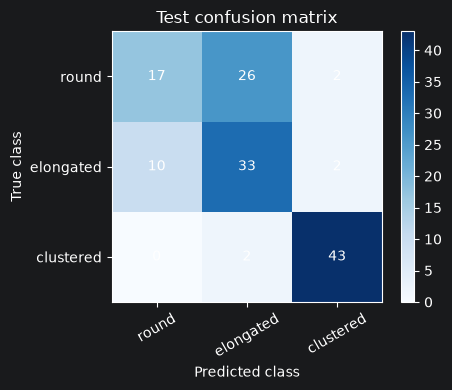

              precision    recall  f1-score   support

       round      0.630     0.378     0.472        45
   elongated      0.541     0.733     0.623        45
   clustered      0.915     0.956     0.935        45

    accuracy                          0.689       135
   macro avg      0.695     0.689     0.677       135
weighted avg      0.695     0.689     0.677       135

Macro F1: 0.6765


In [26]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))

fig, ax = plt.subplots(figsize=(5, 4))
image_handle = ax.imshow(cm, cmap="Blues")
ax.set_title("Test confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30)
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(image_handle, ax=ax)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))
print("Macro F1:", f"{f1_score(y_test, y_pred, average='macro'):.4f}")

## 14. Inspect Predictions and Misclassified Images

A metric summarizes performance; example-level inspection helps explain errors. Review both correct and incorrect predictions. In real scientific workflows, also check whether errors are associated with acquisition conditions, sites, subjects, or annotation practices.

Number of test errors: 42


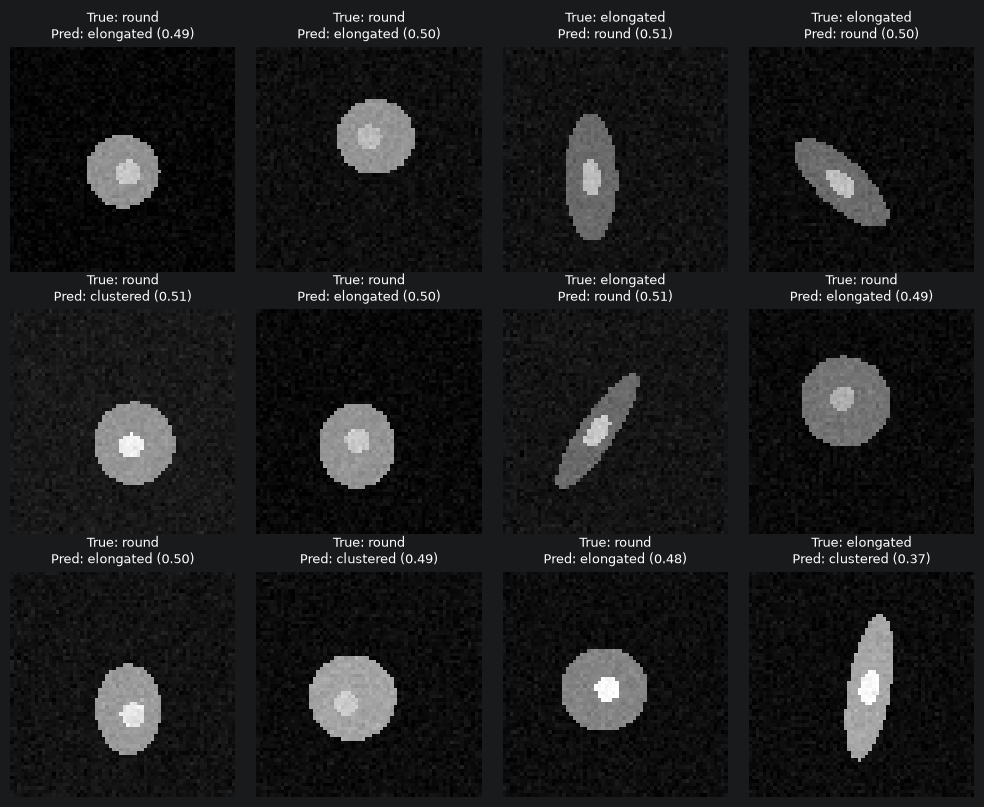

In [27]:
wrong_indices = np.flatnonzero(y_pred != y_test)
print("Number of test errors:", len(wrong_indices))

n_show = min(12, len(wrong_indices))
if n_show > 0:
    selected = wrong_indices[:n_show]
    cols = 4
    rows = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, selected):
        ax.imshow(X_test[idx, ..., 0], cmap="gray", vmin=0, vmax=1)
        true_name = CLASS_NAMES[int(y_test[idx])]
        pred_name = CLASS_NAMES[int(y_pred[idx])]
        confidence = float(np.max(y_prob[idx]))
        ax.set_title(f"True: {true_name}\nPred: {pred_name} ({confidence:.2f})", fontsize=9)
        ax.axis("off")
    for ax in axes[n_show:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test examples in this run.")

## 15. Inspect Intermediate Feature Maps

A feature map shows the response of one learned filter across spatial positions. This can help build intuition about intermediate representations, but it is not a complete explanation of a model's decision. Feature-map intensity should not be interpreted as clinical evidence or causal importance.

First convolution output shape: (1, 64, 64, 32)


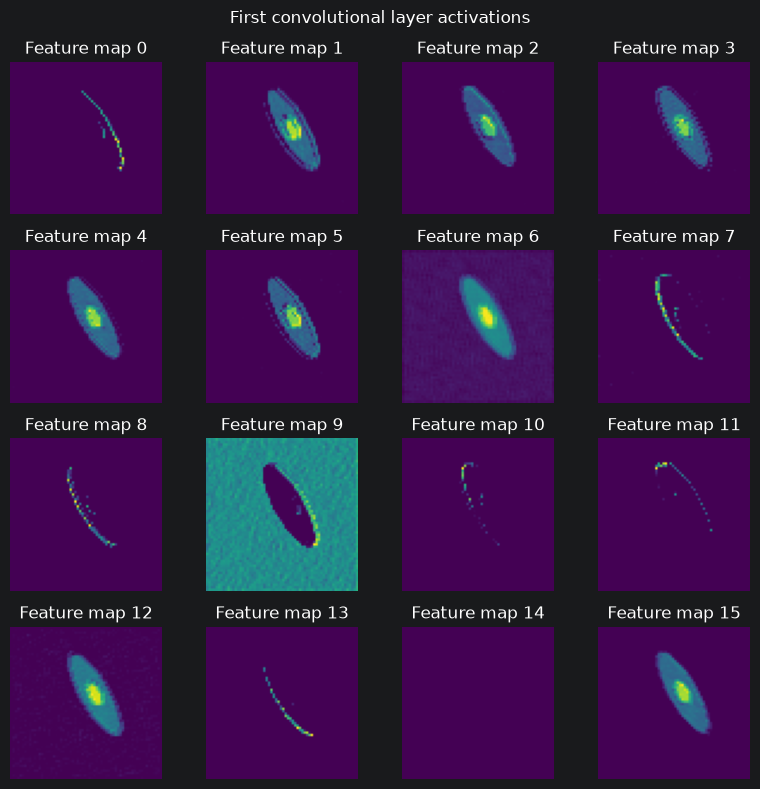

In [28]:
feature_model = keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv1").output,
    name="first_convolution_features",
)

example_batch = X_test[:1]
feature_maps = feature_model.predict(example_batch, verbose=0)
print("First convolution output shape:", feature_maps.shape)

n_maps = min(16, feature_maps.shape[-1])
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[0, ..., i], cmap="viridis")
    ax.set_title(f"Feature map {i}")
    ax.axis("off")
plt.suptitle("First convolutional layer activations")
plt.tight_layout()
plt.show()

### 15.1 Visualize Learned First-Layer Kernels

For a grayscale input, each first-layer kernel has shape $(K_h,K_w,1)$. The values can be displayed as small images. These visualizations are descriptive only; a filter may not correspond neatly to one human-readable concept.

Kernel tensor: (3, 3, 1, 32)
Bias vector: (32,)


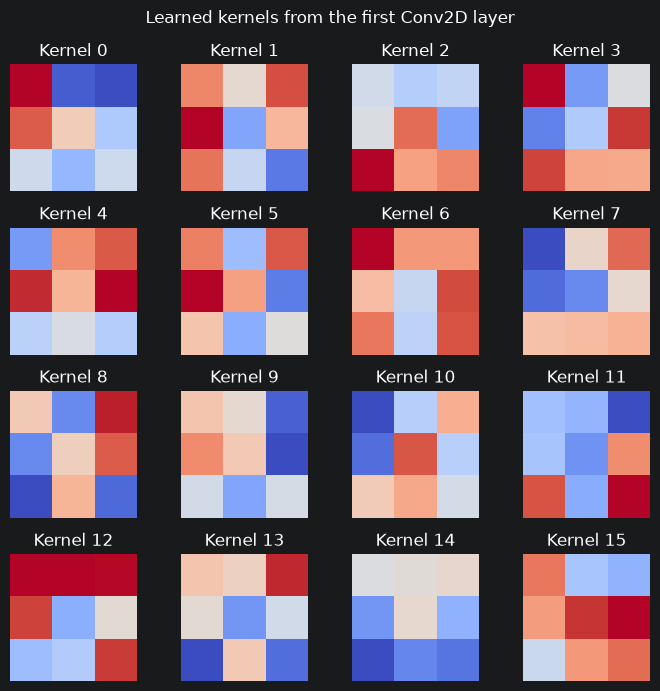

In [29]:
first_conv = model.get_layer("conv1")
kernels, biases = first_conv.get_weights()
print("Kernel tensor:", kernels.shape)
print("Bias vector:", biases.shape)

n_kernels = min(16, kernels.shape[-1])
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.ravel()):
    kernel_image = kernels[:, :, 0, i]
    limit = np.max(np.abs(kernel_image)) + 1e-8
    ax.imshow(kernel_image, cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set_title(f"Kernel {i}")
    ax.axis("off")
plt.suptitle("Learned kernels from the first Conv2D layer")
plt.tight_layout()
plt.show()

## 16. Save and Reload the Model

The recommended Keras model format is the `.keras` file format. Saving is useful for reproducibility and later inference. Store the training configuration, class mapping, dataset-generation settings, and software versions alongside the model.

In [30]:
MODEL_PATH = "synthetic_cell_cnn.keras"
model.save(MODEL_PATH)

reloaded_model = keras.models.load_model(MODEL_PATH)
reloaded_loss, reloaded_accuracy = reloaded_model.evaluate(test_ds, verbose=0)
print("Reloaded model test accuracy:", round(float(reloaded_accuracy), 4))

Reloaded model test accuracy: 0.6889


## 17. Important Design Considerations for Real Imaging Projects

The synthetic example is intentionally simple. When moving to real biological or medical images, the following issues become central:

1. **Patient- or specimen-level splitting:** Images from the same subject should not leak across training and test sets when the intended claim concerns generalization to unseen subjects.
2. **External validation:** Evaluate on data from a genuinely separate source, site, scanner, or time period when possible.
3. **Preprocessing consistency:** Apply the same clinically or scientifically justified preprocessing at training and inference time.
4. **Augmentation validity:** Do not apply transformations that alter the meaning of the image or label.
5. **Class imbalance:** Report per-class metrics and inspect the confusion matrix; accuracy alone may be misleading.
6. **Uncertainty and calibration:** High softmax confidence is not automatically a reliable probability estimate.
7. **Reproducibility:** Record data provenance, split definitions, random seeds, software versions, and model checkpoints.
8. **Responsible interpretation:** A model trained on synthetic teaching data or a narrow dataset should not be presented as a diagnostic system.

These points are especially important for medical imaging, where data leakage and distribution shift can produce overly optimistic performance estimates.

## 18. Key Takeaways

- CNNs preserve spatial structure and reuse kernels across image locations.
- Filters produce feature maps; a layer with more filters produces more output channels.
- Stride and padding determine the spatial output dimensions.
- Pooling downsamples feature maps; it has no trainable kernel parameters in the usual max-pooling form.
- `GlobalAveragePooling2D` can create a compact feature vector before classification.
- Augmentation must preserve the label and should be active only during training.
- A proper workflow separates training, validation, and test data, and reserves the test set for final evaluation.
- Confusion matrices, per-class metrics, and error inspection complement overall accuracy.
- Intermediate activations and kernels are useful visual tools, but they do not by themselves explain a model's decisions.

## 19. Exercises

### Conceptual Questions

1. Why does a convolutional layer usually have fewer parameters than a fully connected layer applied to a large image?
2. What is the difference between `valid` and `same` padding?
3. If stride increases from 1 to 2, what usually happens to the spatial output size?
4. Why does a convolutional layer with 64 filters produce 64 output channels?
5. Compare `Flatten` and `GlobalAveragePooling2D` as classifier heads.
6. Why must augmentation be selected according to the image domain and label definition?
7. Why should the test set not be used to choose the number of epochs or architecture?

### Coding Exercises

1. Modify `cross_correlate_valid` to support a 2D stride tuple and test it on a non-square image.
2. Implement average pooling with NumPy and compare it with max pooling.
3. Change the CNN to use two convolutional blocks. Compare parameter count and validation performance.
4. Replace `GlobalAveragePooling2D` with `Flatten` and compare the number of trainable parameters.
5. Train a model without augmentation and compare its validation performance with the augmented model.
6. Create a fourth synthetic class and update the output layer and evaluation code.
7. Change image size to $96\times96$ and calculate the expected feature-map shapes before running the model.

### Reflection

Which errors would matter most in a real microscopy task, and what additional metadata would you need to determine whether those errors are systematic?

## 20. Further Reading and References

1. TensorFlow, **Convolutional Neural Network (CNN)** tutorial: https://www.tensorflow.org/tutorials/images/cnn
2. Keras 3, **Conv2D layer API**: https://keras.io/api/layers/convolution_layers/convolution2d/
3. Keras 3, **MaxPooling2D layer API**: https://keras.io/api/layers/pooling_layers/max_pooling2d/
4. Keras 3, **Image augmentation layers**: https://keras.io/api/layers/preprocessing_layers/image_augmentation/
5. Keras 3, **Model training APIs**: https://keras.io/api/models/model_training_apis/
6. Keras 3, **Image data loading**: https://keras.io/api/data_loading/image/

---

**End of Notebook 08**